In [17]:
import os
import glob
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

sns.set_theme(style="whitegrid")

print("Week 5 LLMOps environment is ready!")

Week 5 LLMOps environment is ready!


In [1]:
from sentence_transformers import SentenceTransformer
import time

start = time.time()

print("Loading embedding model...", flush=True)

embedder = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding model loaded successfully!")
print("Time taken:", round(time.time() - start, 2), "seconds")

Loading embedding model...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model loaded successfully!
Time taken: 2.77 seconds


In [2]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import time

start = time.time()

print("Loading FLAN-T5 tokenizer...", flush=True)

gen_tok = AutoTokenizer.from_pretrained(
    "google/flan-t5-small"
)

print("Loading FLAN-T5 model...", flush=True)

gen_llm = AutoModelForSeq2SeqLM.from_pretrained(
    "google/flan-t5-small"
)

print("FLAN-T5 model loaded successfully!")
print("Time taken:", round(time.time() - start, 2), "seconds")

Loading FLAN-T5 tokenizer...
Loading FLAN-T5 model...


c:\Users\Hasandi Maheli\OneDrive\Desktop\Virtusa_assesments\Week5_RAG\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Hasandi Maheli\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

c:\Users\Hasandi Maheli\OneDrive\Desktop\Virtusa_assesments\Week5_RAG\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Hasandi Maheli\.cache\huggingface\hub\models--google--flan-t5-small. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

FLAN-T5 model loaded successfully!
Time taken: 37.43 seconds


In [3]:
inputs = gen_tok(
    "Answer briefly: What does RAG stand for?",
    return_tensors="pt"
)

outputs = gen_llm.generate(
    **inputs,
    max_new_tokens=30
)

print(gen_tok.decode(outputs[0], skip_special_tokens=True))

RAG


In [5]:
## Step 1: Load and Chunk the Corpus
# Load embedding model

# Load local language model

import os
import glob
gen_tok = AutoTokenizer.from_pretrained("google/flan-t5-small")
gen_llm = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small")

# Load and chunk the corpus
chunks, sources = [], []

for path in sorted(glob.glob("corpus/*.txt")):

    doc = os.path.basename(path)

    with open(path, "r", encoding="utf-8") as f:
        text = f.read()

    for para in [p.strip() for p in text.split("\n\n") if p.strip()]:

        if len(para.split()) < 4:
            continue

        chunks.append(para)
        sources.append(doc)

print(len(chunks), "chunks from", len(set(sources)), "documents")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


25 chunks from 8 documents


In [6]:
print("Total chunks:", len(chunks))
print("Total documents:", len(set(sources)))

print("\nFirst chunk:")
print(chunks[0])

print("\nSource document:")
print(sources[0])

Total chunks: 25
Total documents: 8

First chunk:
The plant operates eight machines across three production lines. Line A: Press Alpha (M-01) and Press Beta (M-02), both made by Hokuto, plus Lathe Theta (M-08). Line B: Lathe Gamma (M-03), Lathe Delta (M-04), and Press Eta (M-07), all made by Brunner. Line C: Mill Epsilon (M-05) and Mill Zeta (M-06), both made by Voss.

Source document:
01_machine_register.txt


In [7]:
## Step 2: Embed and Retrieve
# Convert all 25 chunks into normalized embeddings
chunk_vecs = embedder.encode(
    chunks,
    normalize_embeddings=True
)

print("Embeddings generated successfully!")
print("Embedding matrix shape:", chunk_vecs.shape)

Embeddings generated successfully!
Embedding matrix shape: (25, 384)


In [8]:
import numpy as np

def retrieve(question, k=3):
    q_vec = embedder.encode(
        [question],
        normalize_embeddings=True
    )[0]

    sims = chunk_vecs @ q_vec

    top = np.argsort(-sims)[:k]

    return [
        (chunks[i], sources[i], float(sims[i]))
        for i in top
    ]

In [9]:
question = "When should I inspect a machine's bearings?"

results = retrieve(question)

for chunk, doc, sim in results:
    print("Similarity:", round(sim, 3))
    print("Source:", doc)
    print("Chunk:", chunk[:200])
    print("-" * 60)

Similarity: 0.773
Source: 02_vibration_guidelines.txt
Chunk: When a machine's vibration exceeds 4.5 mm/s, schedule a bearing inspection at the next opportunity. Rising vibration over several days is a classic sign of bearing wear.
------------------------------------------------------------
Similarity: 0.512
Source: 02_vibration_guidelines.txt
Chunk: When vibration exceeds 6.0 mm/s, stop the machine immediately and raise an unplanned-stop ticket. Running above this level risks a failure that can damage the spindle.
------------------------------------------------------------
Similarity: 0.505
Source: 02_vibration_guidelines.txt
Chunk: Press Eta (M-07) has a known bearing-wear risk and should be watched closely. Its vibration has trended upward in recent monitoring and it is a priority for predictive maintenance.
------------------------------------------------------------


In [10]:
## Step 3: Generate a Grounded Answer
PROMPT_V1 = "Answer the question.\nContext: {ctx}\nQuestion: {q}\nAnswer:"

PROMPT_V2 = (
    "Answer the question using ONLY the context below. If the answer is "
    "not in the context, reply exactly: I don't know.\n\n"
    "Context:\n{ctx}\n\nQuestion: {q}\nAnswer:"
)

print("Both prompt templates created successfully!")

Both prompt templates created successfully!


In [11]:
def generate(prompt, max_new_tokens=50):

    ids = gen_tok(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    out = gen_llm.generate(
        **ids,
        max_new_tokens=max_new_tokens
    )

    return gen_tok.decode(
        out[0],
        skip_special_tokens=True
    )

In [12]:
question = "How often should lathes be serviced?"

hits = retrieve(question)

context = "\n".join(
    c for c, _, _ in hits
)

prompt = PROMPT_V2.format(
    ctx=context,
    q=question
)

answer = generate(prompt)

print("Question:", question)
print("Answer:", answer)

print("\nRetrieved sources:")
for chunk, doc, sim in hits:
    print(doc, "- Similarity:", round(sim, 3))

Question: How often should lathes be serviced?
Answer: every 250 operating hours

Retrieved sources:
03_maintenance_schedule.txt - Similarity: 0.758
03_maintenance_schedule.txt - Similarity: 0.362
07_sensor_calibration.txt - Similarity: 0.355


In [13]:
## Step 4: Retrieval-Confidence Guardrail
import pandas as pd

gold = pd.read_csv("golden_qa.csv").fillna("")

print("Total evaluation questions:", len(gold))
print("\nColumns:", gold.columns.tolist())

display(gold.head())

Total evaluation questions: 17

Columns: ['question', 'reference_answer', 'source_doc', 'answerable']


,question,reference_answer,source_doc,answerable
0,What vibration level means I should inspect a ...,4.5 mm/s,02_vibration_guidelines.txt,1
1,At what vibration reading should a machine be ...,6.0 mm/s,02_vibration_guidelines.txt,1
2,Which machine has a known bearing-wear risk?,Press Eta (M-07),02_vibration_guidelines.txt,1
3,How often should lathes be serviced?,every 250 operating hours,03_maintenance_schedule.txt,1
4,How often should presses be serviced?,every 500 operating hours,03_maintenance_schedule.txt,1


In [22]:
# Calculate top-1 similarity for all 17 questions

gold["top_sim"] = [
    retrieve(q, 1)[0][2]
    for q in gold["question"]
]

print("Similarity scores calculated successfully!")

display(
    gold[["question", "answerable", "top_sim"]]
)

Similarity scores calculated successfully!


,question,answerable,top_sim
0,What vibration level means I should inspect a ...,1,0.768954
1,At what vibration reading should a machine be ...,1,0.738137
2,Which machine has a known bearing-wear risk?,1,0.690091
3,How often should lathes be serviced?,1,0.758302
4,How often should presses be serviced?,1,0.769934
5,What is the machine identifier for Press Eta?,1,0.609249
6,Who manufactures Press Eta?,1,0.566625
7,When does the night shift run?,1,0.738627
8,Which shift has a higher defect rate?,1,0.605872
9,What are the three defect types tracked on the...,1,0.760441


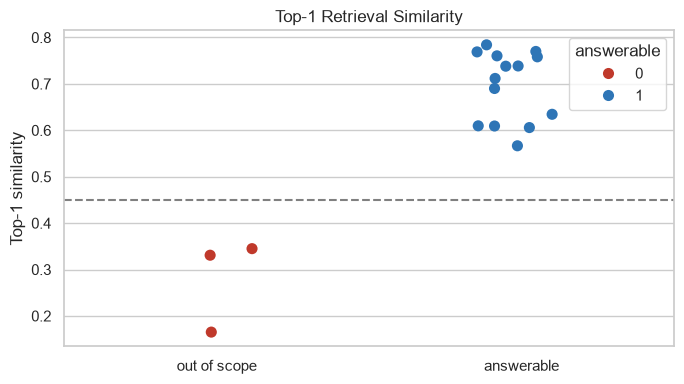

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.stripplot(
    data=gold,
    x="answerable",
    y="top_sim",
    size=8,
    jitter=0.15,
    hue="answerable",
    palette={0: "#C0392B", 1: "#2E75B6"}
)

plt.axhline(
    0.45,
    color="gray",
    linestyle="--",
    label="Guardrail threshold = 0.45"
)

plt.xticks([0, 1], ["out of scope", "answerable"])
plt.title("Top-1 Retrieval Similarity")
plt.ylabel("Top-1 similarity")
plt.xlabel("")

plt.tight_layout()
plt.show()

In [23]:
## Step 5: Wrap the RAG Pipeline as a Service
import time

class RAGService:
    def __init__(self, k=3, tau=0.45, template=PROMPT_V2):
        self.k = k
        self.tau = tau
        self.template = template

    def ask(self, question):
        t0 = time.perf_counter()

        hits = retrieve(question, self.k)
        top_sim = hits[0][2]

        # Guardrail: refuse low-confidence questions
        if top_sim < self.tau:
            return {
                "answer": "I don't know based on the handbook.",
                "refused": True,
                "sources": [],
                "top_sim": round(top_sim, 3),
                "prompt_chars": 0,
                "latency_ms": round(
                    (time.perf_counter() - t0) * 1000, 1
                )
            }

        # Generate an answer from retrieved context
        ctx = "\n".join(c for c, _, _ in hits)

        answer = generate(
            self.template.format(
                ctx=ctx,
                q=question
            )
        )

        return {
            "answer": answer,
            "refused": False,
            "sources": sorted(set(d for _, d, _ in hits)),
            "top_sim": round(top_sim, 3),
            "prompt_chars": len(ctx),
            "latency_ms": round(
                (time.perf_counter() - t0) * 1000, 1
            )
        }


In [24]:
service = RAGService()

print("QUESTION 1: In-scope")
print(service.ask("Who manufactures Press Eta?"))

print("\nQUESTION 2: Out-of-scope")
print(service.ask("What colour is the factory floor painted?"))

QUESTION 1: In-scope
{'answer': 'Brunner', 'refused': False, 'sources': ['01_machine_register.txt', '02_vibration_guidelines.txt'], 'top_sim': 0.567, 'prompt_chars': 669, 'latency_ms': 1634.2}

QUESTION 2: Out-of-scope
{'answer': "I don't know based on the handbook.", 'refused': True, 'sources': [], 'top_sim': 0.331, 'prompt_chars': 0, 'latency_ms': 28.0}


In [25]:
# Verify the manufacturer of Press Eta

for chunk, source in zip(chunks, sources):
    if "Press Eta" in chunk:
        print("Source:", source)
        print("Content:", chunk)
        print("-" * 60)

Source: 01_machine_register.txt
Content: The plant operates eight machines across three production lines. Line A: Press Alpha (M-01) and Press Beta (M-02), both made by Hokuto, plus Lathe Theta (M-08). Line B: Lathe Gamma (M-03), Lathe Delta (M-04), and Press Eta (M-07), all made by Brunner. Line C: Mill Epsilon (M-05) and Mill Zeta (M-06), both made by Voss.
------------------------------------------------------------
Source: 01_machine_register.txt
Content: Press Eta, machine identifier M-07, is the oldest press on the floor. It was installed in 2013 and is manufactured by Brunner. It runs on Line B and is rated at 45 kW.
------------------------------------------------------------
Source: 02_vibration_guidelines.txt
Content: Press Eta (M-07) has a known bearing-wear risk and should be watched closely. Its vibration has trended upward in recent monitoring and it is a priority for predictive maintenance.
------------------------------------------------------------
Source: 08_escalatio

In [26]:
## Step 6: Observability - Latency, Tokens, and Cost
# Step 6: Observability

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Example hosted API price (USD per 1,000 tokens)
PRICE_PER_1K_TOKENS = 0.0005

# Test questions
questions = [
    "At what vibration reading should a machine be stopped?",
    "How often should presses be serviced?",
    "When does the night shift run?",
    "How many cars fit in the staff car park?"
]

# Store observability logs
logs = []

for q in questions:

    # Ask the RAG assistant
    r = service.ask(q)

    # Estimate prompt tokens
    tokens = r["prompt_chars"] / 4

    # Record metrics
    logs.append({
        "question": q,
        "refused": r["refused"],
        "top_sim": r["top_sim"],
        "latency_ms": r["latency_ms"],
        "tokens": int(tokens),
        "cost_usd": round(
            tokens / 1000 * PRICE_PER_1K_TOKENS, 6
        )
    })

# Convert logs to DataFrame
log_df = pd.DataFrame(logs)

# Display results
display(log_df)

,question,refused,top_sim,latency_ms,tokens,cost_usd
0,At what vibration reading should a machine be ...,False,0.748,608.2,110,0.000055
1,How often should presses be serviced?,False,0.770,381.0,140,0.000070
2,When does the night shift run?,False,0.739,541.0,117,0.000059
3,How many cars fit in the staff car park?,True,0.165,30.3,0,0.000000


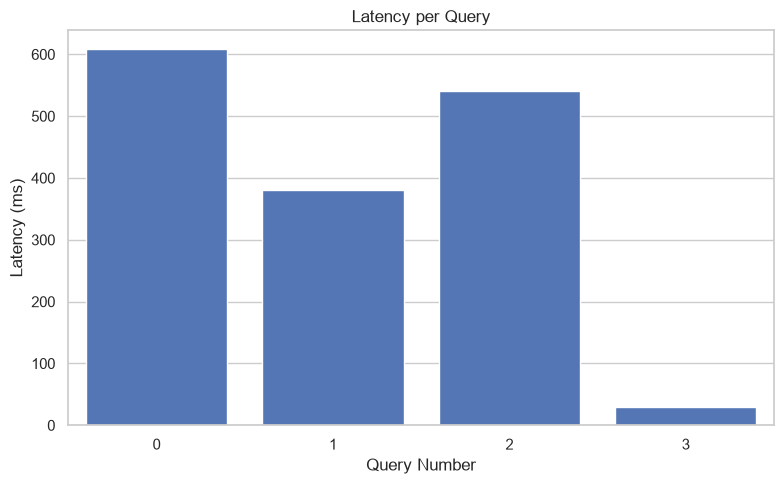

In [27]:
### 6.1 Latency Analysis
plt.figure(figsize=(8, 5))

sns.barplot(
    data=log_df,
    x=log_df.index,
    y="latency_ms",
    color="#4472C4"
)

plt.title("Latency per Query")
plt.xlabel("Query Number")
plt.ylabel("Latency (ms)")

plt.tight_layout()
plt.show()

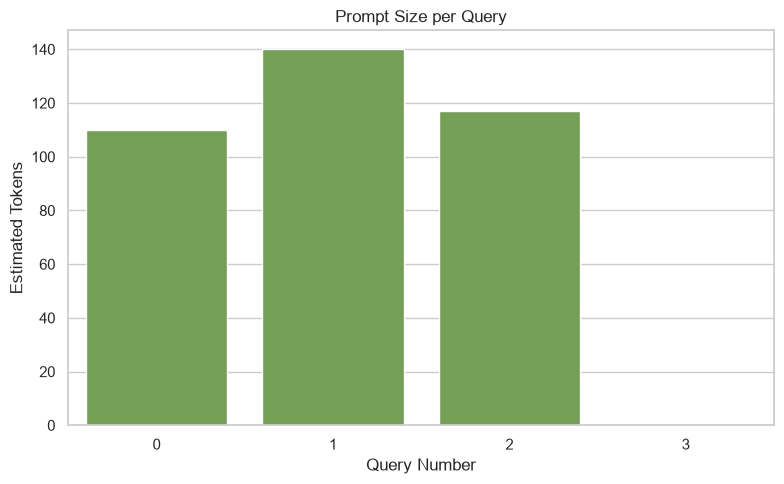

In [28]:
### 6.2 Estimated Token Usage
plt.figure(figsize=(8, 5))

sns.barplot(
    data=log_df,
    x=log_df.index,
    y="tokens",
    color="#70AD47"
)

plt.title("Prompt Size per Query")
plt.xlabel("Query Number")
plt.ylabel("Estimated Tokens")

plt.tight_layout()
plt.show()

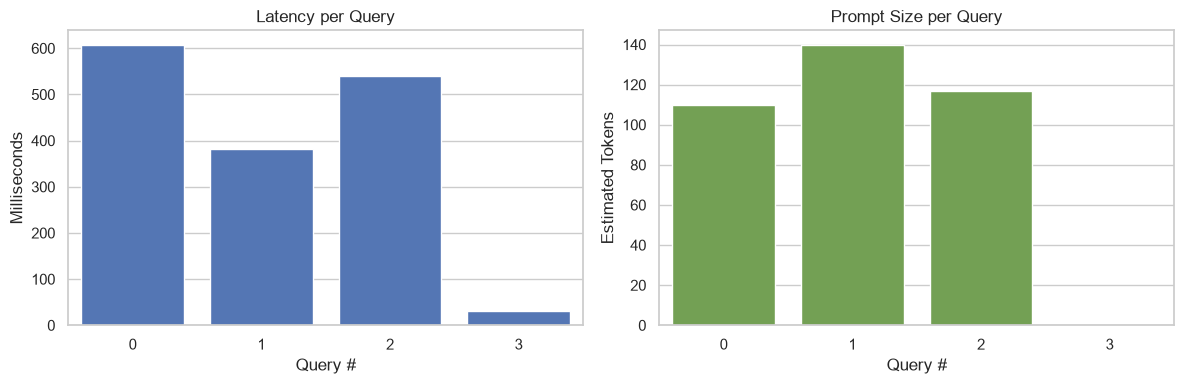

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Latency chart
sns.barplot(
    data=log_df,
    x=log_df.index,
    y="latency_ms",
    color="#4472C4",
    ax=axes[0]
)

axes[0].set_title("Latency per Query")
axes[0].set_xlabel("Query #")
axes[0].set_ylabel("Milliseconds")

# Token usage chart
sns.barplot(
    data=log_df,
    x=log_df.index,
    y="tokens",
    color="#70AD47",
    ax=axes[1]
)

axes[1].set_title("Prompt Size per Query")
axes[1].set_xlabel("Query #")
axes[1].set_ylabel("Estimated Tokens")

plt.tight_layout()
plt.show()

In [30]:
print("OBSERVABILITY SUMMARY")
print("-" * 40)

print(
    "Average latency:",
    round(log_df["latency_ms"].mean(), 2),
    "ms"
)

print(
    "Total estimated tokens:",
    log_df["tokens"].sum()
)

print(
    "Total estimated API cost: $",
    round(log_df["cost_usd"].sum(), 6)
)

print(
    "Refused questions:",
    log_df["refused"].sum()
)

print(
    "Answered questions:",
    (~log_df["refused"]).sum()
)

OBSERVABILITY SUMMARY
----------------------------------------
Average latency: 390.12 ms
Total estimated tokens: 367
Total estimated API cost: $ 0.000184
Refused questions: 1
Answered questions: 3


In [31]:
## Step 7: Evaluation Harness
def semantic_sim(a, b):
    va, vb = embedder.encode(
        [a, b],
        normalize_embeddings=True
    )

    return float(va @ vb)

print("Semantic similarity function created successfully!")

Semantic similarity function created successfully!


In [32]:
def evaluate(svc):
    hit = quality = n_ans = 0
    refused_ok = n_unans = 0

    for _, row in gold.iterrows():

        r = svc.ask(row["question"])

        if row["answerable"] == 1:
            n_ans += 1

            if row["source_doc"] in r["sources"]:
                hit += 1

            quality += semantic_sim(
                r["answer"],
                row["reference_answer"]
            )

        else:
            n_unans += 1

            if r["refused"]:
                refused_ok += 1

    return {
        "retrieval_hit_rate": round(hit / n_ans, 3),
        "answer_quality": round(quality / n_ans, 3),
        "refusal_accuracy": round(refused_ok / n_unans, 3)
    }

print("Evaluation function created successfully!")

Evaluation function created successfully!


In [33]:
print("Starting RAG evaluation...")

results = evaluate(service)

print("\nEvaluation Results")
print("-" * 40)

for metric, value in results.items():
    print(f"{metric}: {value:.3f}")

Starting RAG evaluation...

Evaluation Results
----------------------------------------
retrieval_hit_rate: 1.000
answer_quality: 0.975
refusal_accuracy: 1.000


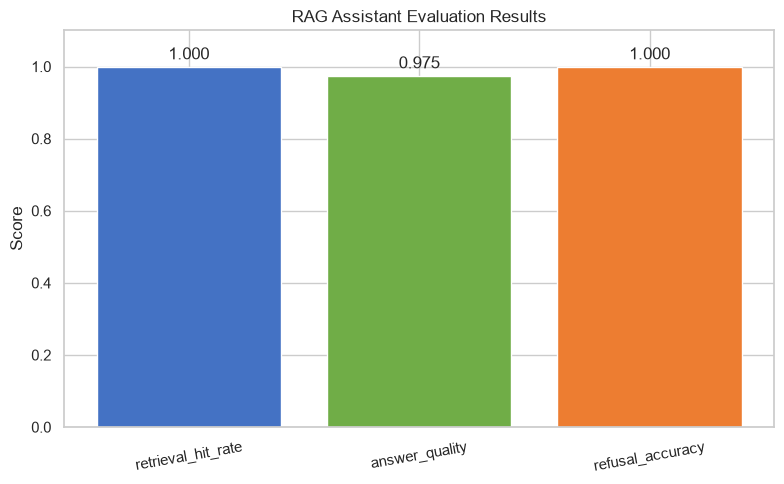

In [34]:
import matplotlib.pyplot as plt

metrics = list(results.keys())
values = list(results.values())

plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics,
    values,
    color=["#4472C4", "#70AD47", "#ED7D31"]
)

plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.title("RAG Assistant Evaluation Results")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

In [35]:
## Step 8: Prompt Versioning
def answer_quality_for(template):
    svc = RAGService(template=template)

    total = 0
    n = 0

    for _, row in gold[gold.answerable == 1].iterrows():

        r = svc.ask(row["question"])

        total += semantic_sim(
            r["answer"],
            row["reference_answer"]
        )

        n += 1

    return total / n

In [36]:
q1 = answer_quality_for(PROMPT_V1)
q2 = answer_quality_for(PROMPT_V2)

print("Prompt v1 answer quality:", round(q1, 3))
print("Prompt v2 answer quality:", round(q2, 3))

Prompt v1 answer quality: 0.916
Prompt v2 answer quality: 0.975


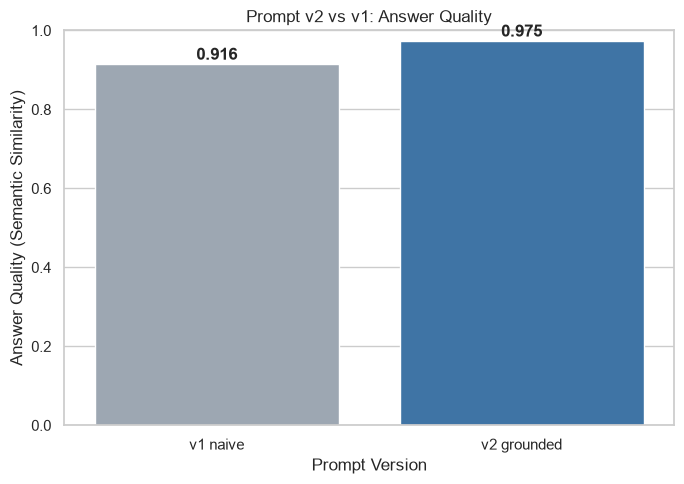

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=["v1 naive", "v2 grounded"],
    y=[q1, q2],
    hue=["v1 naive", "v2 grounded"],
    palette=["#9AA7B5", "#2E75B6"],
    legend=False
)

plt.ylim(0, 1)
plt.ylabel("Answer Quality (Semantic Similarity)")
plt.xlabel("Prompt Version")
plt.title("Prompt v2 vs v1: Answer Quality")

for i, value in enumerate([q1, q2]):
    plt.text(
        i,
        min(value + 0.01, 0.99),
        f"{value:.3f}",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [38]:
## Step 9: Failure Analysis and Tuning

In [41]:
diagnostics = []

for _, row in gold.iterrows():
    result = service.ask(row["question"])

    expected_source_found = (
        row["source_doc"] in result["sources"]
    )

    diagnostics.append({
        "question": row["question"],
        "answerable": row["answerable"],
        "refused": result["refused"],
        "top_sim": result["top_sim"],
        "source_found": expected_source_found,
        "generated_answer": result["answer"]
    })

diagnostic_df = pd.DataFrame(diagnostics)

display(diagnostic_df)

,question,answerable,refused,top_sim,source_found,generated_answer
0,What vibration level means I should inspect a ...,1,False,0.769,True,4.5 mm/s
1,At what vibration reading should a machine be ...,1,False,0.738,True,6.0 mm/s
2,Which machine has a known bearing-wear risk?,1,False,0.690,True,Press Eta (M-07)
3,How often should lathes be serviced?,1,False,0.758,True,every 250 operating hours
4,How often should presses be serviced?,1,False,0.770,True,every 500 operating hours
5,What is the machine identifier for Press Eta?,1,False,0.609,True,M-07
6,Who manufactures Press Eta?,1,False,0.567,True,Brunner
7,When does the night shift run?,1,False,0.739,True,18:00 to 06:00
8,Which shift has a higher defect rate?,1,False,0.606,True,night shift
9,What are the three defect types tracked on the...,1,False,0.760,True,"scratches, cracks, and pits"
